# 4_gridsearch_lines_bands: grid search on 7 lines, grid vs perturbed bands

Fits restricted to the 7 lines that carried most of the misfit of the off-grid targets in `3_gridsearch_lines.ipynb` (cell 9: 4300.442, 4309.112, 4326.971, 4377.159, 4380.460, 4384.773, 4396.258 A).

- **Grid**: the 210 models of notebook 3 (polar caps / equatorial / bands at +/-30 deg; i = 0-90 step 15; visible ff 0.05-0.50 step 0.05), read from its dense cache and cut to the 7 line windows. One model is re-simulated on the windows alone and must match the cache.
- **Perturbed targets**: 20 grid-like disks off the grid nodes (seed 0): geometry uniform over the three families, i uniform on 0-90 deg, target visible ff uniform on 0.05-0.50, and for the band pair a centre latitude uniform on 20-40 deg. Simulated on the line windows only.
- **Fit**: chi^2 over the window bins against the 210 models, noiseless and at SNR 100 / 30 / 10 / 3 (sigma = I / SNR per 0.0087 A bin, 200 realisations each). Recovered = the grid model with the target's geometry family (a +/-lat pair counts as `bands_pm30`), the nearest i node, and, among those, the nearest *actual* visible ff.
- Spectra are divided by their own mean over the 7 windows.
- Line windows, common bins and the simulation setup are notebook 3's, copied unchanged.

Run from `actress_highres/actress/` (all paths are relative to it).

Using existing test_phot_ssd_4300_4400.txt
Using existing test_fac_200G_4300_4400.txt
11473 wavelengths, 4300.0980-4399.8999 A; images at 4384.7640 A (I0_fac / I0_phot = 2.245)


354 lines deeper than 0.05 below the 2.0 A running maximum; windows padded by 7 bins (0.0587 A); they cover 77.9% of the 11457 bins

7 selected lines, 314 fit bins (2.7% of the common bins)
 lambda (A)  depth            window (A)  bins
  4300.4420  0.448  4300.3044- 4300.5624    31
  4309.1118  0.954  4309.0429- 4309.4307    46
  4326.9712  0.953  4326.7722- 4327.3780    71
  4377.1586  0.940  4377.0098- 4377.3162    36
  4380.4602  0.837  4380.3376- 4380.5741    28
  4384.7727  0.950  4384.5096- 4385.2200    82
  4396.2583  0.898  4396.1880- 4396.3550    20


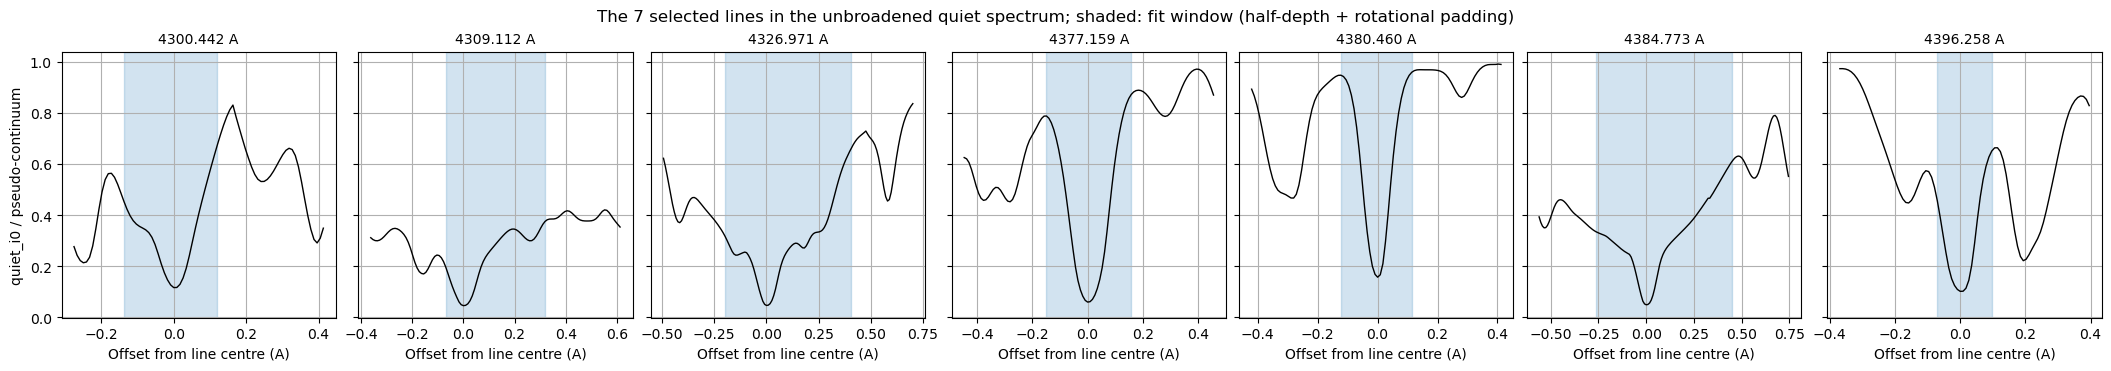

In [1]:
import os
import sys
import time
import multiprocessing as mp
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.ndimage import maximum_filter1d
from scipy.signal import find_peaks, peak_widths
from scipy.special import erfc
import actress.contrasts as contrst

# ----- simulation setup, from 1_gridsearch.ipynb (validated there against sim_spectrum + process_disk_directory) -----
# Same LD files, wavelength grid, bins, band geometry, filling-factor solver and in-memory Doppler
# binning as 1_gridsearch, so the spectra here are directly comparable with its caches.
import time
import actress as ac
import actress.run_actress_notebook as actr

grid_phot_file = './inputs/limb_files/average_intensities_ssd_driftcorrected.txt'   # real SSD, with lines
grid_fac_file = './inputs/limb_files/average_intensities_200G_driftcorrected.txt'
grid_phot_ld_file = 'test_phot_ssd_4300_4400.txt'
grid_fac_ld_file = 'test_fac_200G_4300_4400.txt'
grid_ld_law = 'power2'
# The files span 430.00034-440.00055 nm. contrast() takes delta_freq from both neighbours of
# each kept sample, so the two end samples cannot be used; start and stop one sample inside.
grid_wav_lower = 4.3001e-7   # m
grid_wav_higher = 4.3999e-7  # m

grid_v_eq = 4000                  # m/s, equatorial rotation velocity, fixed for every run
grid_res3d = 5                    # healpix nside = 2^5
grid_res2d = 200                  # pixels across the projected disk
# At nside 32 the visible ff moves in steps of up to ~0.026 (one healpix ring), so the target
# can only be hit to about half a step. Anything further off means the solver failed.
grid_ff_tolerance = 0.02
grid_n_workers = 8                # processes; this runs on a shared login node

# ----- limb-darkening fits over 430-440 nm, every native sample -----
grid_file_wav_nm = pd.read_csv(grid_phot_file, sep=r'\s+', comment='#').values[:, 0]   # nm
grid_log_grid_wav = contrst.wav_nm_to_m(contrst.log_uniform_grid(grid_file_wav_nm, R=500000))   # m, the grid contrast() uses
grid_indx_low, grid_indx_high = contrst.wav_limits(list(grid_log_grid_wav), grid_wav_lower, grid_wav_higher)
if grid_indx_low < 1 or grid_indx_high > len(grid_log_grid_wav) - 2:
    raise ValueError(f"Window indices {grid_indx_low}-{grid_indx_high} leave no neighbour for delta_freq")
# N such that contrast()'s step round((high - low) / N) is 1: every 0.0087 A (~600 m/s) sample is
# kept, rather than every 2nd as in the 4376 cells, so the 4000 m/s broadening spans ~13 bins.
grid_N_ld = grid_indx_high - grid_indx_low

contrst.validate_inputs(grid_fac_file, grid_phot_file, grid_wav_lower, grid_wav_higher, graphs=False)
for source_file, ld_file in ((grid_phot_file, grid_phot_ld_file), (grid_fac_file, grid_fac_ld_file)):
    if os.path.exists(ld_file):
        print(f"Using existing {ld_file}")
        continue
    t_start = time.time()
    contrst.contrast(source_file, wav_lower=grid_wav_lower, wav_higher=grid_wav_higher, N=grid_N_ld,
                     ld_law=grid_ld_law, save=ld_file, graphs=False)
    print(f"Wrote {ld_file} ({time.time() - t_start:.0f} s)")
contrst.validate_outputs(grid_fac_ld_file, grid_phot_ld_file, graphs=False)

grid_phot_ld = np.loadtxt(grid_phot_ld_file)   # columns: wavelength (m), I0, c1, c2
grid_fac_ld = np.loadtxt(grid_fac_ld_file)
if len(grid_phot_ld) != grid_indx_high - grid_indx_low + 1:
    raise ValueError(f"{grid_phot_ld_file} has {len(grid_phot_ld)} rows, expected every sample "
                     f"{grid_indx_low}-{grid_indx_high}; it was made with different settings")

# Wavelength labels exactly as run_actress_notebook formats them, and the bins
# process_disk_directory builds from them: centres are the sampled wavelengths themselves.
grid_wavelength_texts = [f"{wav * 1e10:.4f}" for wav in grid_phot_ld[:, 0]]
grid_input_wavelengths = np.array([float(text) for text in grid_wavelength_texts])   # Angstrom
grid_midpoints = 0.5 * (grid_input_wavelengths[:-1] + grid_input_wavelengths[1:])
grid_bin_edges = np.concatenate((
    [grid_input_wavelengths[0] - (grid_input_wavelengths[1] - grid_input_wavelengths[0]) / 2],
    grid_midpoints,
    [grid_input_wavelengths[-1] + (grid_input_wavelengths[-1] - grid_input_wavelengths[-2]) / 2]))
grid_bin_edges_rounded = np.round(grid_bin_edges, 10)

# Images are shown where the facula is brightest relative to the photosphere at disk centre.
grid_image_index = int(np.argmax(grid_fac_ld[:, 1] / grid_phot_ld[:, 1]))
print(f"{len(grid_input_wavelengths)} wavelengths, {grid_input_wavelengths[0]:.4f}-{grid_input_wavelengths[-1]:.4f} A; "
      f"images at {grid_input_wavelengths[grid_image_index]:.4f} A "
      f"(I0_fac / I0_phot = {grid_fac_ld[grid_image_index, 1] / grid_phot_ld[grid_image_index, 1]:.3f})")

_grid_ld_params = actr.Transitparams()
_grid_ld_params.ld = grid_ld_law
grid_ld_func = actr.Transitsim(_grid_ld_params).ld_law   # the same law function sim_spectrum passes to actress


# ----- geometry -----
def band_strips(geometry, half_width):
    """(lower, upper) addstrip latitudes in deg for a band family of half-width `half_width` (deg)."""
    if geometry == 'polar_caps':
        return [(-90, -90 + half_width), (90 - half_width, 90)]
    if geometry == 'equatorial':
        return [(-half_width, half_width)]
    if geometry == 'bands_pm30':
        return [(30 - half_width, 30 + half_width), (-30 - half_width, -30 + half_width)]
    raise ValueError(f"Unknown geometry {geometry}")

# Beyond these half-widths a band edge passes a pole and addstrip reflects it back silently.
grid_max_half_width = {'polar_caps': 90, 'equatorial': 90, 'bands_pm30': 60}   # deg


def build_grid_simulator(strips, faculae):
    """actress Simulator with the given strips [(lower, upper)] and faculae [(r, lon, lat)], deg."""
    sim = ac.Simulator(faculae=[], spots=[], fac_strips=[], spot_strips=[])   # explicit lists: the defaults are shared between instances
    sim.setxsize(grid_res2d)
    sim.setresolution(grid_res3d)
    for lower, upper in strips:
        if lower < -90 or upper > 90:
            raise ValueError(f"Strip ({lower}, {upper}) leaves +/-90 deg and would be reflected by addstrip")
        sim.addstrip(lower=lower, upper=upper, feature='fac')
    for r, lon, lat in faculae:
        sim.addfeature(r=r, lon=lon, lat=lat, feature='fac')
    return sim


def visible_fill(strips, faculae, inc):
    return build_grid_simulator(strips, faculae).getdiscfill(feature='fac', inc=inc)


def solve_half_width(geometry, inc, target_ff):
    """Half-width (deg) whose visible ff is closest to target_ff, by bisection (ff grows with width)."""
    lower, upper = 0.0, float(grid_max_half_width[geometry])
    if visible_fill(band_strips(geometry, upper), [], inc) < target_ff:
        raise ValueError(f"{geometry} at i = {inc} cannot reach visible ff {target_ff}")
    for _ in range(40):
        middle = (lower + upper) / 2
        if visible_fill(band_strips(geometry, middle), [], inc) < target_ff:
            lower = middle
        else:
            upper = middle
    # ff is a step function of width (whole healpix pixels), so take the closer side of the step.
    ff_lower = visible_fill(band_strips(geometry, lower), [], inc)
    ff_upper = visible_fill(band_strips(geometry, upper), [], inc)
    if abs(ff_lower - target_ff) < abs(ff_upper - target_ff):
        half_width, ff = lower, ff_lower
    else:
        half_width, ff = upper, ff_upper
    if abs(ff - target_ff) > grid_ff_tolerance:
        raise ValueError(f"{geometry} at i = {inc}: closest visible ff {ff:.4f} misses target {target_ff}")
    return half_width, ff


# ----- spectrum of one run, binned as process_disk_directory does -----
def set_grid_ld(sim, k):
    """Limb-darkening dict for wavelength row k, built as Transitsim.actress_run builds it."""
    sim.setld({'phot': [grid_phot_ld[k, 1], grid_phot_ld[k, 2], grid_phot_ld[k, 3], None, None],
               'spot': [12955331.717385203, 0.3, 0.2, 0.1, 0.1],   # unused in faconly mode
               'fac': [grid_fac_ld[k, 1], grid_fac_ld[k, 2], grid_fac_ld[k, 3], None, None],
               'func': grid_ld_func})


def simulate_grid_spectrum(run):
    """
    Disk-integrated spectrum at rotation angle 0 for one run.

    Returns (bin_centers (A), mean intensity per bin, disk image at grid_image_index).
    Same steps as disk_utils.process_disk_directory: shift each on-disk pixel by its Doppler
    shift, drop points within max_shift of the window ends, bin to the input wavelengths
    (edges rounded to 1e-10 A), keep only bins fully inside the trimmed range, average.
    """
    sim = build_grid_simulator(run['strips'], run['faculae'])
    n_bins = len(grid_input_wavelengths)
    # The shift map is -lambda v_los / c, so its maximum is at the longest wavelength; it is
    # needed before the loop to trim points exactly as process_disk_directory does.
    set_grid_ld(sim, n_bins - 1)
    _, shift_longest = sim.rotate_lc(v_eq=grid_v_eq, inc=run['inc'], N=1, mode='faconly',
                                     wavelength=grid_wavelength_texts[-1], returndisc=True)
    max_shift = shift_longest.max()   # A
    trim_lower = grid_input_wavelengths.min() + max_shift
    trim_upper = grid_input_wavelengths.max() - max_shift

    sums = np.zeros(n_bins)
    counts = np.zeros(n_bins, dtype=np.int64)
    largest_shift_seen = -np.inf
    image = None
    for k, wavelength_text in enumerate(grid_wavelength_texts):
        set_grid_ld(sim, k)
        disks, shift = sim.rotate_lc(v_eq=grid_v_eq, inc=run['inc'], N=1, mode='faconly',
                                     wavelength=wavelength_text, returndisc=True)
        disk = disks[0]
        largest_shift_seen = max(largest_shift_seen, shift.max())
        on_disk = disk > 0   # rotate_lc sets the off-disk background to 0
        observed_wavelength = grid_input_wavelengths[k] + shift[on_disk]
        intensity = disk[on_disk]
        kept = (observed_wavelength >= trim_lower) & (observed_wavelength <= trim_upper)
        point_bins = np.searchsorted(grid_bin_edges_rounded, np.round(observed_wavelength[kept], 10), side='right') - 1
        in_range = (point_bins >= 0) & (point_bins < n_bins)
        sums += np.bincount(point_bins[in_range], weights=intensity[kept][in_range], minlength=n_bins)
        counts += np.bincount(point_bins[in_range], minlength=n_bins)
        if k == grid_image_index:
            image = disk.copy()

    if largest_shift_seen != max_shift:
        raise ValueError(f"{run['name']}: max shift {largest_shift_seen} is not at the longest wavelength ({max_shift})")
    valid_bins = (grid_bin_edges[:-1] >= trim_lower) & (grid_bin_edges[1:] <= trim_upper)
    if np.any(counts[valid_bins] == 0):
        raise ValueError(f"{run['name']}: {np.sum(counts[valid_bins] == 0)} empty wavelength bins")
    return grid_input_wavelengths[valid_bins], sums[valid_bins] / counts[valid_bins], image


# ----- caches from notebooks 1 and 3, and notebook 3's common bins -----
dense_cache_file = (f'./outputs/gridsearch/3_gridsearch_dense_v{grid_v_eq}_res3d{grid_res3d}_res2d{grid_res2d}'
                    f'_{grid_wav_lower * 1e10:.1f}_{grid_wav_higher * 1e10:.1f}_i15_ff005.npz')
dense_cache = np.load(dense_cache_file)
dense_config = np.array([grid_v_eq, grid_res3d, grid_res2d, len(grid_input_wavelengths)], dtype=float)
if not np.array_equal(dense_cache['config'], dense_config):
    raise ValueError(f"{dense_cache_file} was made with settings {dense_cache['config']}, expected {dense_config}")
dense_run_names = list(dense_cache['run_names'])
grid_cache = np.load('./outputs/gridsearch/1_gridsearch_v4000_res3d5_res2d200_4300.1_4399.9_randomseed0.npz')
band_cache = np.load('./outputs/gridsearch/1_gridsearch_randombands_v4000_res3d5_res2d200_4300.1_4399.9_seeds1-3.npz')

# Common bins built from the same spectra as in notebook 3, so the line windows below come out identical.
quiet_bins, quiet_spectrum = grid_cache['bins_quiet_i0'], grid_cache['spectrum_quiet_i0']
common_bins = quiet_bins
spectra_bins = [dense_cache[f'bins_{name}'] for name in dense_run_names] + [grid_cache['bins_random']]
spectra_bins += [band_cache[f'bins_{name}'] for name in band_cache['run_names'] if name.startswith('random_bands')]
for bins in spectra_bins:
    common_bins = np.intersect1d(common_bins, bins)
n_bins = len(common_bins)


def on_common_bins(bins, spectrum, label):
    on_common = np.isin(bins, common_bins)
    if on_common.sum() != len(common_bins):
        raise ValueError(f"{label} does not cover all common bins")
    return spectrum[on_common]


# ----- absorption lines in the unbroadened quiet spectrum -----
# Pseudo-continuum: running maximum over 2 A. 430-440 nm has no truly line-free stretch, so depths
# are relative to the local maximum, not to a true continuum.
continuum_window = 2.0     # A
line_min_depth = 0.05      # minimum prominence, as a fraction of the pseudo-continuum
bin_width = np.median(np.diff(common_bins))                  # A, ~0.0087
max_rotational_shift = grid_v_eq / 3e8 * common_bins.max()   # A, with the c simulator.rotate_lc uses
pad_bins = int(np.ceil(max_rotational_shift / bin_width))

quiet_common = on_common_bins(quiet_bins, quiet_spectrum, 'quiet_i0')
pseudo_continuum = maximum_filter1d(quiet_common, size=int(round(continuum_window / bin_width)), mode='nearest')
depth = 1 - quiet_common / pseudo_continuum
line_centres, properties = find_peaks(depth, prominence=line_min_depth)
line_wavelengths = common_bins[line_centres]
line_depths = properties['prominences']
n_lines = len(line_centres)

# Window: half-depth points (measured from each line's prominence base), padded by the largest
# Doppler shift so the broadened line fits at any inclination. Where windows of neighbouring lines
# overlap, the shared bins go to the nearer line centre, so windows are disjoint and each bin's
# chi^2 is counted once: per-line Delta then adds up exactly for any combination of lines.
_, _, left_half, right_half = peak_widths(depth, line_centres, rel_height=0.5)
line_left = np.maximum(np.floor(left_half).astype(int) - pad_bins, 0)
line_right = np.minimum(np.ceil(right_half).astype(int) + pad_bins, n_bins - 1)   # inclusive
for l in range(n_lines - 1):
    if line_right[l] >= line_left[l + 1]:
        split = (line_centres[l] + line_centres[l + 1]) // 2
        line_right[l] = split
        line_left[l + 1] = split + 1
if np.any(line_left > line_centres) or np.any(line_right < line_centres):
    raise ValueError("Splitting overlapping windows pushed a window off its own line centre")

in_any_line = np.zeros(n_bins, dtype=bool)
for left, right in zip(line_left, line_right):
    in_any_line[left:right + 1] = True
print(f"{n_lines} lines deeper than {line_min_depth} below the {continuum_window} A running maximum; windows padded by "
      f"{pad_bins} bins ({max_rotational_shift:.4f} A); they cover {in_any_line.mean() * 100:.1f}% of the {n_bins} bins")


# ----- the 7 lines: every line in the worst-fitting top 5 of any off-grid target, notebook 3 cell 9 -----
selected_line_wavelengths = [4300.442, 4309.112, 4326.971, 4377.159, 4380.460, 4384.773, 4396.258]   # A, as printed there
selected_lines = []
for wavelength in selected_line_wavelengths:
    nearest = int(np.argmin(np.abs(line_wavelengths - wavelength)))
    if abs(line_wavelengths[nearest] - wavelength) > bin_width / 2:
        raise ValueError(f"No detected line within half a bin of {wavelength} A (nearest {line_wavelengths[nearest]:.4f} A)")
    selected_lines.append(nearest)
n_selected = len(selected_lines)
window_bins = [np.arange(line_left[l], line_right[l] + 1) for l in selected_lines]   # common-bin indices, per line
fit_bins = np.concatenate(window_bins)   # windows are disjoint, so no bin is counted twice
fit_wavelengths = common_bins[fit_bins]   # A
window_of_fit_bin = np.concatenate([np.full(len(bins), k) for k, bins in enumerate(window_bins)])

print(f"\n{n_selected} selected lines, {len(fit_bins)} fit bins ({len(fit_bins) / n_bins * 100:.1f}% of the common bins)")
print(f"{'lambda (A)':>11s} {'depth':>6s} {'window (A)':>21s} {'bins':>5s}")
for l, bins in zip(selected_lines, window_bins):
    print(f"{line_wavelengths[l]:11.4f} {line_depths[l]:6.3f} {common_bins[bins[0]]:10.4f}-{common_bins[bins[-1]]:10.4f} {len(bins):5d}")

fig, axes = plt.subplots(1, n_selected, figsize=(3 * n_selected, 3.6), sharey=True, constrained_layout=True)
for ax, l, bins in zip(axes, selected_lines, window_bins):
    around = (common_bins >= common_bins[bins[0]] - 0.3) & (common_bins <= common_bins[bins[-1]] + 0.3)
    ax.plot(common_bins[around] - line_wavelengths[l], quiet_common[around] / pseudo_continuum[around], color='k', linewidth=1)
    ax.axvspan(common_bins[bins[0]] - line_wavelengths[l], common_bins[bins[-1]] - line_wavelengths[l], color='tab:blue', alpha=0.2)
    ax.set_title(f"{line_wavelengths[l]:.3f} A", fontsize=10)
    ax.set_xlabel('Offset from line centre (A)')
    ax.grid(True)
axes[0].set_ylabel('quiet_i0 / pseudo-continuum')
fig.suptitle('The 7 selected lines in the unbroadened quiet spectrum; shaded: fit window (half-depth + rotational padding)')
plt.show()


426 of 11473 input wavelengths are simulated per run (windows +/- 8 samples)


/rds/general/user/dsy24/home/miniforge3/envs/actress_highres1/lib/python3.9/site-packages/actress-1.0-py3.9.egg/actress/run_actress_notebook.py:63: RuntimeWarning: divide by zero encountered in power
  y = I0 * (1-(a*(1-(mu**b))))


Windowed re-simulation of bands_pm30_ff0.30_i90 vs the dense cache: max |relative difference| 0.00e+00 (8 s)


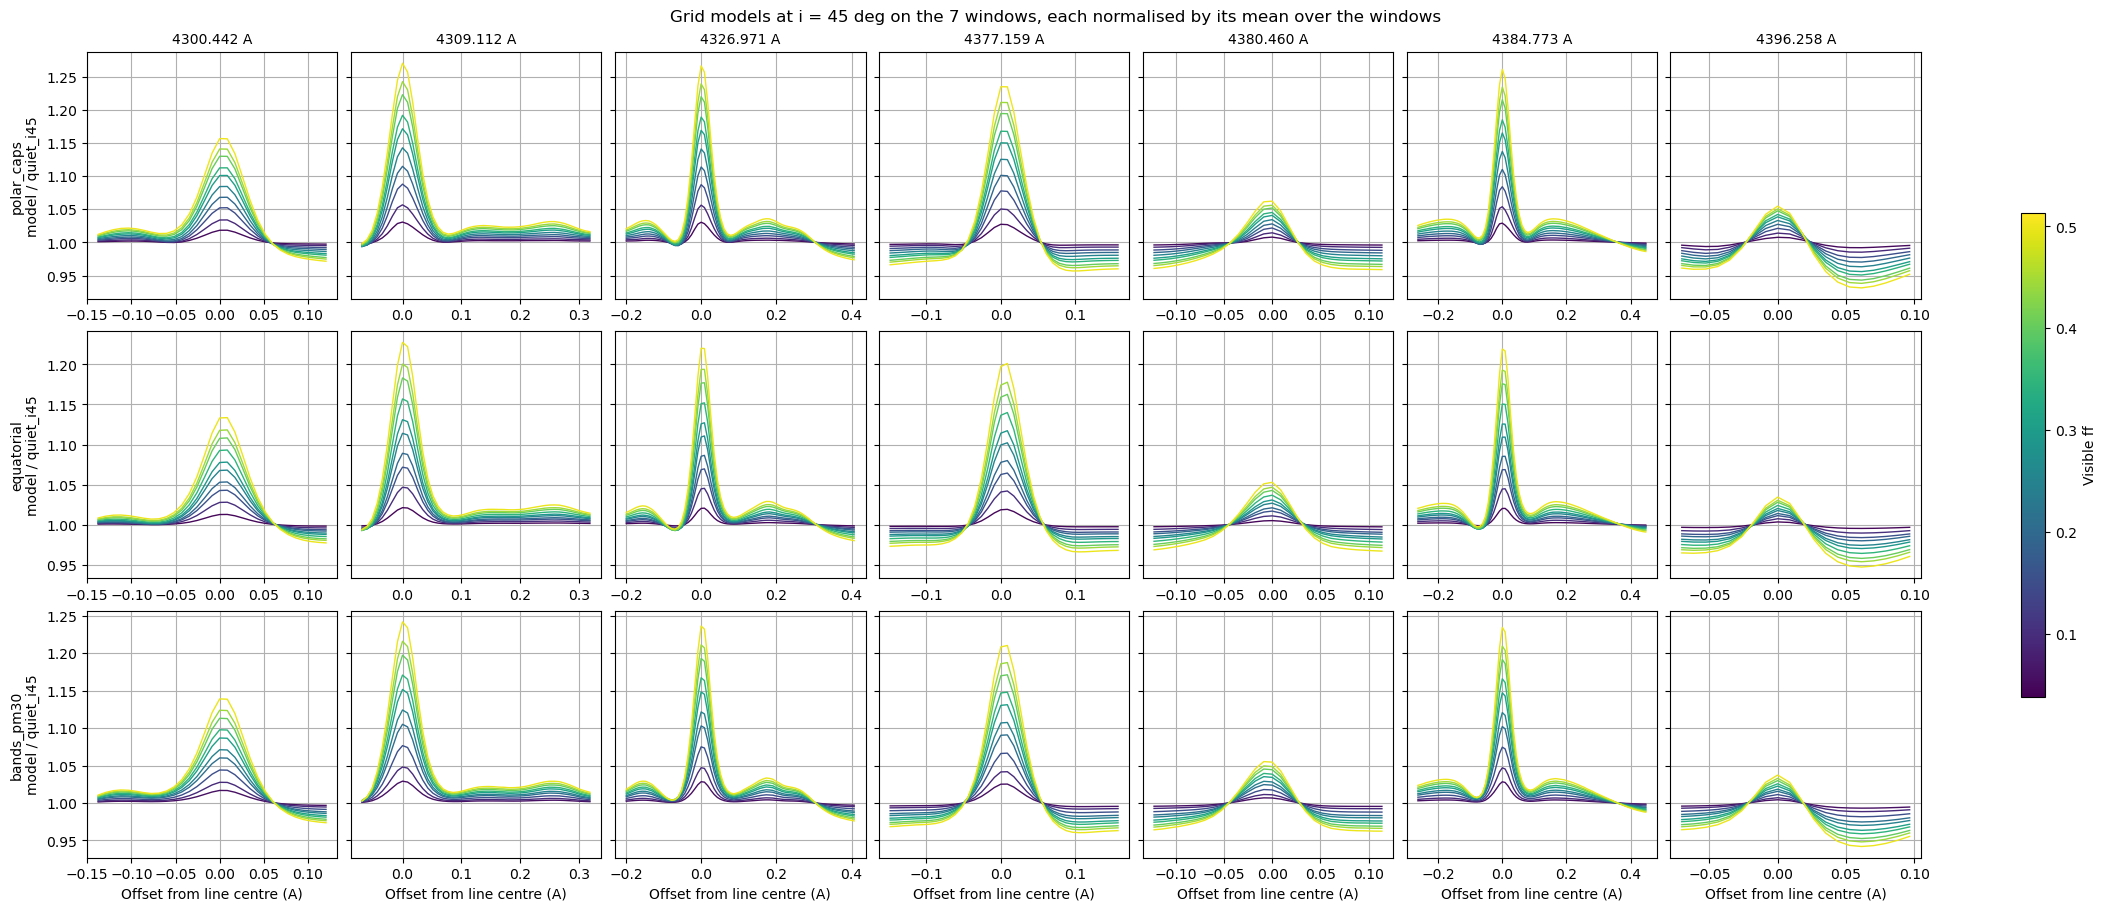

In [2]:
# ----- grid models on the 7 line windows -----
model_names = dense_run_names
model_geometry = np.array([name.split('_ff')[0] for name in model_names])
model_target_ff = np.array([float(name.split('_ff')[1].split('_i')[0]) for name in model_names])   # nominal
model_inc = np.array([float(name.rsplit('_i', 1)[1]) for name in model_names])   # deg
model_ff = dense_cache['visible_ffs']                                            # actual visible ff
model_half_width = dense_cache['half_widths']                                    # deg
n_models = len(model_names)
model_raw = np.array([on_common_bins(dense_cache[f'bins_{name}'], dense_cache[f'spectrum_{name}'], name)[fit_bins]
                      for name in model_names])
model_matrix = model_raw / model_raw.mean(axis=1, keepdims=True)   # (n_models, n_fit_bins), each / its own mean


# ----- simulation on the line windows only -----
# A bin receives light only from input wavelengths within the largest Doppler shift of it, so each window
# needs its own bins plus input_pad input samples on each side; the rest of 430-440 nm is not simulated.
# The full-range simulation's trimming (max_shift from each end of 430-440 nm) cannot touch these bins:
# checked below. Each bin then gets the same contributions in the same order as in simulate_grid_spectrum.
input_pad = int(np.ceil(max_rotational_shift / bin_width + 0.5))
fit_grid_index = np.searchsorted(grid_input_wavelengths, fit_wavelengths)
if not np.array_equal(grid_input_wavelengths[fit_grid_index], fit_wavelengths):
    raise ValueError("Fit bins are not input wavelengths")
if (fit_wavelengths.min() - bin_width / 2 < grid_input_wavelengths.min() + max_rotational_shift
        or fit_wavelengths.max() + bin_width / 2 > grid_input_wavelengths.max() - max_rotational_shift):
    raise ValueError("A fit window is within the end trimming of the full-range simulation")
window_input_indices = np.unique(np.concatenate(
    [np.arange(fit_grid_index[window_of_fit_bin == k].min() - input_pad, fit_grid_index[window_of_fit_bin == k].max() + input_pad + 1)
     for k in range(n_selected)]))
print(f"{len(window_input_indices)} of {len(grid_input_wavelengths)} input wavelengths are simulated per run "
      f"(windows +/- {input_pad} samples)")


def simulate_line_windows(run):
    """(mean intensity in each fit bin, disk image at grid_image_index) for one run, simulating only the window inputs."""
    sim = build_grid_simulator(run['strips'], run['faculae'])
    n_grid = len(grid_input_wavelengths)
    sums = np.zeros(n_grid)
    counts = np.zeros(n_grid, dtype=np.int64)
    largest_shift_seen = 0.0
    for k in window_input_indices:
        set_grid_ld(sim, k)
        disks, shift = sim.rotate_lc(v_eq=grid_v_eq, inc=run['inc'], N=1, mode='faconly',
                                     wavelength=grid_wavelength_texts[k], returndisc=True)
        disk = disks[0]
        on_disk = disk > 0   # rotate_lc sets the off-disk background to 0
        largest_shift_seen = max(largest_shift_seen, np.abs(shift[on_disk]).max())
        observed_wavelength = grid_input_wavelengths[k] + shift[on_disk]
        point_bins = np.searchsorted(grid_bin_edges_rounded, np.round(observed_wavelength, 10), side='right') - 1
        in_range = (point_bins >= 0) & (point_bins < n_grid)
        sums += np.bincount(point_bins[in_range], weights=disk[on_disk][in_range], minlength=n_grid)
        counts += np.bincount(point_bins[in_range], minlength=n_grid)
    if largest_shift_seen > (input_pad - 0.5) * bin_width:
        raise ValueError(f"{run['name']}: shift {largest_shift_seen:.4f} A exceeds the {input_pad}-sample input padding")
    if np.any(counts[fit_grid_index] == 0):
        raise ValueError(f"{run['name']}: {np.sum(counts[fit_grid_index] == 0)} empty fit bins")
    set_grid_ld(sim, grid_image_index)
    disks, _ = sim.rotate_lc(v_eq=grid_v_eq, inc=run['inc'], N=1, mode='faconly',
                             wavelength=grid_wavelength_texts[grid_image_index], returndisc=True)
    return sums[fit_grid_index] / counts[fit_grid_index], disks[0].copy()


# Validation: i = 90 has the largest shifts, so it is the hardest case for the padding.
validation_name = 'bands_pm30_ff0.30_i90'
validation_index = model_names.index(validation_name)
validation_run = {'name': validation_name, 'inc': model_inc[validation_index], 'faculae': [],
                  'strips': band_strips(model_geometry[validation_index], model_half_width[validation_index])}
t_start = time.time()
validation_spectrum, _ = simulate_line_windows(validation_run)
validation_difference = np.max(np.abs(validation_spectrum / model_raw[validation_index] - 1))
print(f"Windowed re-simulation of {validation_name} vs the dense cache: max |relative difference| "
      f"{validation_difference:.2e} ({time.time() - t_start:.0f} s)")
if validation_difference > 1e-12:
    raise ValueError("The windowed simulation does not reproduce the full-range one")

# ----- plot: every grid model at i = 45, relative to the quiet star at i = 45 -----
quiet_45 = on_common_bins(grid_cache['bins_quiet_i45'], grid_cache['spectrum_quiet_i45'], 'quiet_i45')[fit_bins]
quiet_45 = quiet_45 / quiet_45.mean()
dense_geometries = ['polar_caps', 'equatorial', 'bands_pm30']
ff_colour = plt.cm.viridis((model_ff - model_ff.min()) / (model_ff.max() - model_ff.min()))
fig, axes = plt.subplots(len(dense_geometries), n_selected, figsize=(3 * n_selected, 3 * len(dense_geometries)),
                         sharey='row', constrained_layout=True)
for row, geometry in enumerate(dense_geometries):
    for column, l in enumerate(selected_lines):
        ax = axes[row, column]
        in_window = window_of_fit_bin == column
        for m in np.where((model_geometry == geometry) & (model_inc == 45))[0]:
            ax.plot(fit_wavelengths[in_window] - line_wavelengths[l], model_matrix[m, in_window] / quiet_45[in_window],
                    color=ff_colour[m], linewidth=1)
        ax.grid(True)
        if row == 0:
            ax.set_title(f"{line_wavelengths[l]:.3f} A", fontsize=10)
        if row == len(dense_geometries) - 1:
            ax.set_xlabel('Offset from line centre (A)')
    axes[row, 0].set_ylabel(f"{geometry}\nmodel / quiet_i45")
fig.colorbar(plt.cm.ScalarMappable(cmap='viridis', norm=plt.Normalize(model_ff.min(), model_ff.max())),
             ax=axes, label='Visible ff', shrink=0.6)
fig.suptitle('Grid models at i = 45 deg on the 7 windows, each normalised by its mean over the windows')
plt.show()


20 targets (0 draws redrawn: target ff unreachable)
target                    i (deg) lat (deg) visible ff  expected grid model (visible ff)
perturbed00_bands_pmlat     24.28     20.33     0.0694  bands_pm30_ff0.05_i30 (0.0543)
perturbed01_equatorial      73.19       nan     0.4590  equatorial_ff0.45_i75 (0.4398)
perturbed02_equatorial      65.65       nan     0.2998  equatorial_ff0.30_i60 (0.3074)
perturbed03_equatorial      84.16       nan     0.4267  equatorial_ff0.40_i90 (0.4036)
perturbed04_bands_pmlat     77.17     34.59     0.0659  bands_pm30_ff0.05_i75 (0.0463)
perturbed05_polar_caps      15.81       nan     0.4414  polar_caps_ff0.45_i15 (0.4426)
perturbed06_polar_caps      26.97       nan     0.2480  polar_caps_ff0.25_i30 (0.2412)
perturbed07_equatorial       2.55       nan     0.1042  equatorial_ff0.10_i0 (0.1035)
perturbed08_polar_caps      58.25       nan     0.3211  polar_caps_ff0.30_i60 (0.2921)
perturbed09_bands_pmlat     34.53     39.62     0.5005  bands_pm30_ff0.50_i30

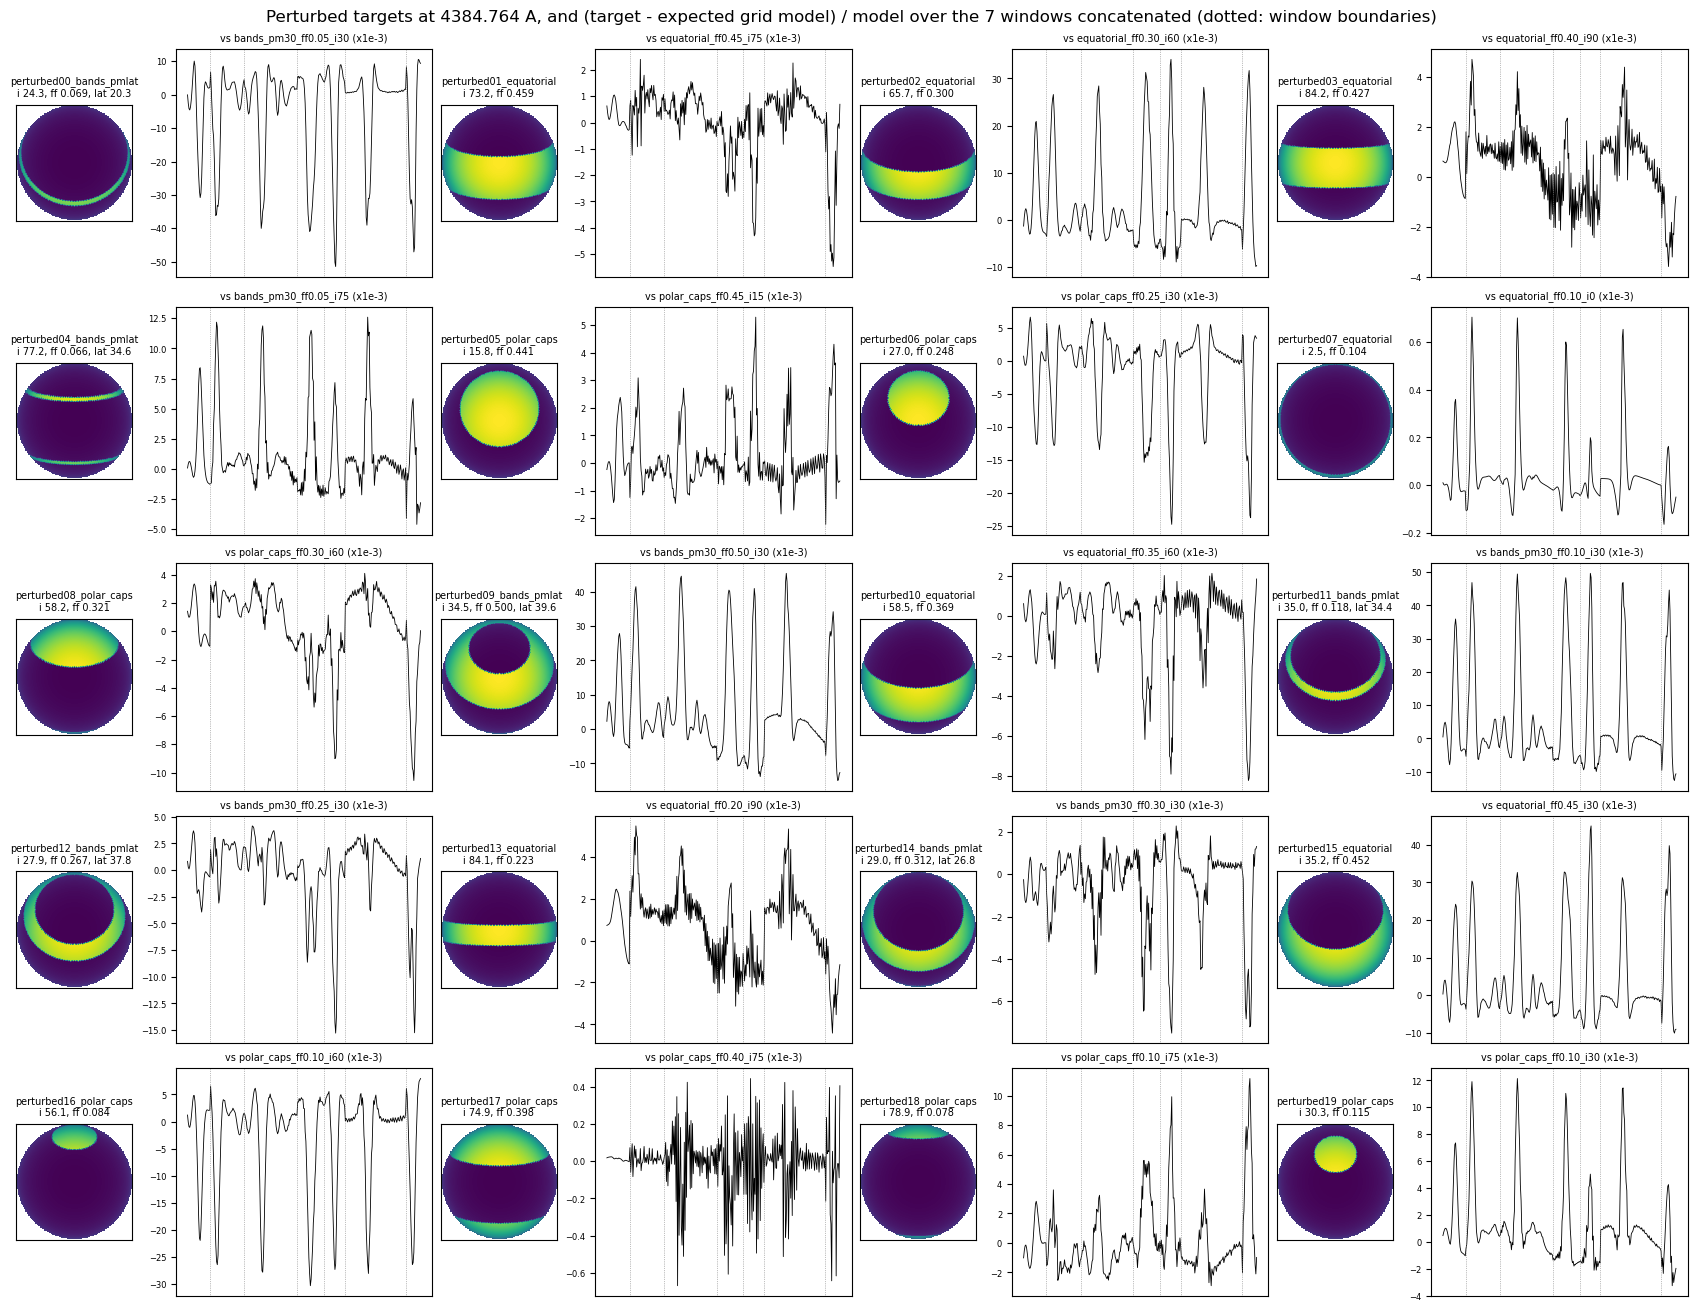

In [3]:
# ----- perturbed targets: grid-like bands off the grid nodes -----
perturbed_seed = 0
n_perturbed = 20
perturbed_geometries = ['polar_caps', 'equatorial', 'bands_pmlat']
perturbed_inc_range = (0.0, 90.0)     # deg, uniform in i (not cos i), so targets spread evenly between the 15 deg nodes
perturbed_ff_range = (0.05, 0.50)     # visible ff, the grid's range
perturbed_lat_range = (20.0, 40.0)    # deg, centre latitude of the band pair; the grid has only 30
grid_incs = np.unique(model_inc)       # deg
perturbed_cache_file = (f'./outputs/gridsearch/4_gridsearch_lines_perturbed_v{grid_v_eq}_res3d{grid_res3d}_res2d{grid_res2d}'
                        f'_{n_selected}lines_seed{perturbed_seed}_n{n_perturbed}.npz')


def perturbed_strips(geometry, half_width, centre_lat):
    """(lower, upper) addstrip latitudes in deg; bands_pmlat is bands_pm30 with the centre latitude free."""
    if geometry == 'bands_pmlat':
        return [(centre_lat - half_width, centre_lat + half_width), (-centre_lat - half_width, -centre_lat + half_width)]
    return band_strips(geometry, half_width)


def perturbed_max_half_width(geometry, centre_lat):
    if geometry == 'bands_pmlat':
        return 90.0 - centre_lat   # beyond this a band edge passes the pole and addstrip reflects it
    return float(grid_max_half_width[geometry])


def solve_perturbed_half_width(geometry, centre_lat, inc, target_ff):
    """solve_half_width's bisection, with the band-pair latitude free."""
    lower, upper = 0.0, perturbed_max_half_width(geometry, centre_lat)
    for _ in range(40):
        middle = (lower + upper) / 2
        if visible_fill(perturbed_strips(geometry, middle, centre_lat), [], inc) < target_ff:
            lower = middle
        else:
            upper = middle
    ff_lower = visible_fill(perturbed_strips(geometry, lower, centre_lat), [], inc)
    ff_upper = visible_fill(perturbed_strips(geometry, upper, centre_lat), [], inc)
    if abs(ff_lower - target_ff) < abs(ff_upper - target_ff):
        half_width, ff = lower, ff_lower
    else:
        half_width, ff = upper, ff_upper
    if abs(ff - target_ff) > grid_ff_tolerance:
        raise ValueError(f"{geometry} (lat {centre_lat}) at i = {inc}: closest visible ff {ff:.4f} misses target {target_ff}")
    return half_width, ff


rng = np.random.default_rng(perturbed_seed)
perturbed_runs = []
n_redrawn = 0   # draws whose target ff the geometry cannot reach at that inclination
while len(perturbed_runs) < n_perturbed:
    geometry = perturbed_geometries[int(rng.integers(len(perturbed_geometries)))]
    inc = rng.uniform(*perturbed_inc_range)
    target_ff = rng.uniform(*perturbed_ff_range)
    centre_lat = rng.uniform(*perturbed_lat_range) if geometry == 'bands_pmlat' else np.nan
    widest = perturbed_strips(geometry, perturbed_max_half_width(geometry, centre_lat), centre_lat)
    if visible_fill(widest, [], inc) < target_ff:
        n_redrawn += 1
        continue
    half_width, ff = solve_perturbed_half_width(geometry, centre_lat, inc, target_ff)
    grid_geometry = 'bands_pm30' if geometry == 'bands_pmlat' else geometry
    # Expected best model: same family, nearest i node, and among those the nearest actual visible ff.
    inc_node = grid_incs[np.argmin(np.abs(grid_incs - inc))]
    candidates = np.where((model_geometry == grid_geometry) & (model_inc == inc_node))[0]
    expected = int(candidates[np.argmin(np.abs(model_ff[candidates] - ff))])
    perturbed_runs.append({'name': f'perturbed{len(perturbed_runs):02d}_{geometry}', 'geometry': geometry,
                           'grid_geometry': grid_geometry, 'inc': inc, 'centre_lat': centre_lat, 'target_ff': target_ff,
                           'visible_ff': ff, 'half_width': half_width, 'faculae': [],
                           'strips': perturbed_strips(geometry, half_width, centre_lat),
                           'inc_node': inc_node, 'expected': expected})
print(f"{n_perturbed} targets ({n_redrawn} draws redrawn: target ff unreachable)")
print(f"{'target':24s} {'i (deg)':>8s} {'lat (deg)':>9s} {'visible ff':>10s}  expected grid model (visible ff)")
for run in perturbed_runs:
    print(f"{run['name']:24s} {run['inc']:8.2f} {run['centre_lat']:9.2f} {run['visible_ff']:10.4f}  "
          f"{model_names[run['expected']]} ({model_ff[run['expected']]:.4f})")

# ----- simulate, or load the cache -----
perturbed_names = np.array([run['name'] for run in perturbed_runs])
perturbed_config = np.array([grid_v_eq, grid_res3d, grid_res2d, perturbed_seed, n_perturbed, input_pad,
                             *perturbed_inc_range, *perturbed_ff_range, *perturbed_lat_range], dtype=float)
perturbed_strip_edges = np.array([edge for run in perturbed_runs for strip in run['strips'] for edge in strip] +
                                 [run['inc'] for run in perturbed_runs])
perturbed_raw = {}
perturbed_images = {}
if os.path.exists(perturbed_cache_file):
    cached = np.load(perturbed_cache_file)
    if not (np.array_equal(cached['run_names'], perturbed_names) and np.array_equal(cached['config'], perturbed_config)
            and np.array_equal(cached['strip_edges'], perturbed_strip_edges)
            and np.array_equal(cached['fit_wavelengths'], fit_wavelengths)):
        raise ValueError(f"{perturbed_cache_file} was made with different runs or settings. "
                         "Delete or rename it by hand if it should be replaced.")
    for name in perturbed_names:
        perturbed_raw[name] = cached[f'spectrum_{name}']
        perturbed_images[name] = cached[f'image_{name}']
    print(f"\nLoaded {len(perturbed_raw)} spectra from {perturbed_cache_file}")
else:
    t_start = time.time()
    ctx = mp.get_context('fork')
    with ctx.Pool(processes=grid_n_workers) as pool:
        results = pool.map(simulate_line_windows, perturbed_runs, chunksize=1)
    for run, (spectrum, image) in zip(perturbed_runs, results):
        perturbed_raw[run['name']] = spectrum
        perturbed_images[run['name']] = image
    print(f"\nSimulated {n_perturbed} runs x {len(window_input_indices)} wavelengths in {(time.time() - t_start) / 60:.1f} min")
    to_save = {'run_names': perturbed_names, 'config': perturbed_config, 'strip_edges': perturbed_strip_edges,
               'fit_wavelengths': fit_wavelengths, 'incs': np.array([run['inc'] for run in perturbed_runs]),
               'visible_ffs': np.array([run['visible_ff'] for run in perturbed_runs]),
               'centre_lats': np.array([run['centre_lat'] for run in perturbed_runs])}
    for name in perturbed_names:
        to_save[f'spectrum_{name}'] = perturbed_raw[name]
        to_save[f'image_{name}'] = perturbed_images[name]
    np.savez(perturbed_cache_file, **to_save)
    print(f"Wrote {perturbed_cache_file}")

for name, spectrum in perturbed_raw.items():
    if not np.all(np.isfinite(spectrum)) or np.any(spectrum <= 0):
        raise ValueError(f"{name}: non-finite or non-positive intensity in the spectrum")
target_matrix = np.array([perturbed_raw[name] for name in perturbed_names])
target_matrix = target_matrix / target_matrix.mean(axis=1, keepdims=True)   # (n_perturbed, n_fit_bins)

# ----- plot: each target's disk, and its offset from the expected grid model on the 7 windows -----
images = [perturbed_images[name].copy() for name in perturbed_names]
for image in images:
    image[image == 0] = np.nan   # off-disk background
image_vmin = min(np.nanmin(image) for image in images)
image_vmax = max(np.nanmax(image) for image in images)
n_columns = 4   # targets per row; each target takes a disk panel and a residual panel
n_rows = int(np.ceil(n_perturbed / n_columns))
fig, axes = plt.subplots(n_rows, 2 * n_columns, figsize=(4.2 * n_columns, 2.6 * n_rows), squeeze=False,
                         gridspec_kw={'width_ratios': [1, 2.2] * n_columns}, constrained_layout=True)
window_edges = np.where(np.diff(window_of_fit_bin) != 0)[0] + 0.5
for t, run in enumerate(perturbed_runs):
    ax_disk, ax_residual = axes[t // n_columns, 2 * (t % n_columns)], axes[t // n_columns, 2 * (t % n_columns) + 1]
    ax_disk.imshow(images[t], cmap='viridis', vmin=image_vmin, vmax=image_vmax)
    ax_disk.set_xticks([])
    ax_disk.set_yticks([])
    lat_text = f", lat {run['centre_lat']:.1f}" if run['geometry'] == 'bands_pmlat' else ''
    ax_disk.set_title(f"{run['name']}\ni {run['inc']:.1f}, ff {run['visible_ff']:.3f}{lat_text}", fontsize=7)
    expected_row = model_matrix[run['expected']]
    ax_residual.plot((target_matrix[t] - expected_row) / expected_row * 1e3, color='k', linewidth=0.6)
    for edge in window_edges:
        ax_residual.axvline(edge, color='grey', linewidth=0.5, linestyle=':')
    ax_residual.set_title(f"vs {model_names[run['expected']]} (x1e-3)", fontsize=7)
    ax_residual.tick_params(labelsize=6)
    ax_residual.set_xticks([])
for ax in axes.flat[2 * n_perturbed:]:
    ax.axis('off')
fig.suptitle(f'Perturbed targets at {grid_input_wavelengths[grid_image_index]:.3f} A, and (target - expected grid model) / model '
             'over the 7 windows concatenated (dotted: window boundaries)')
plt.show()


Fraction of fits returning the expected grid model (chance: 1/210 = 0.005)
target                   expected model           noiseless best           noiseless   SNR 100    SNR 30    SNR 10     SNR 3
perturbed00_bands_pmlat  bands_pm30_ff0.05_i30    equatorial_ff0.25_i15         0.00      0.00      0.00      0.01      0.02
perturbed01_equatorial   equatorial_ff0.45_i75    equatorial_ff0.45_i75         1.00      1.00      0.73      0.20      0.01
perturbed02_equatorial   equatorial_ff0.30_i60    bands_pm30_ff0.35_i60         0.00      0.00      0.00      0.01      0.03
perturbed03_equatorial   equatorial_ff0.40_i90    equatorial_ff0.40_i90         1.00      0.97      0.48      0.14      0.04
perturbed04_bands_pmlat  bands_pm30_ff0.05_i75    bands_pm30_ff0.10_i75         0.00      0.01      0.14      0.05      0.01
perturbed05_polar_caps   polar_caps_ff0.45_i15    polar_caps_ff0.45_i15         1.00      1.00      0.94      0.40      0.04
perturbed06_polar_caps   polar_caps_ff0.25_i30    

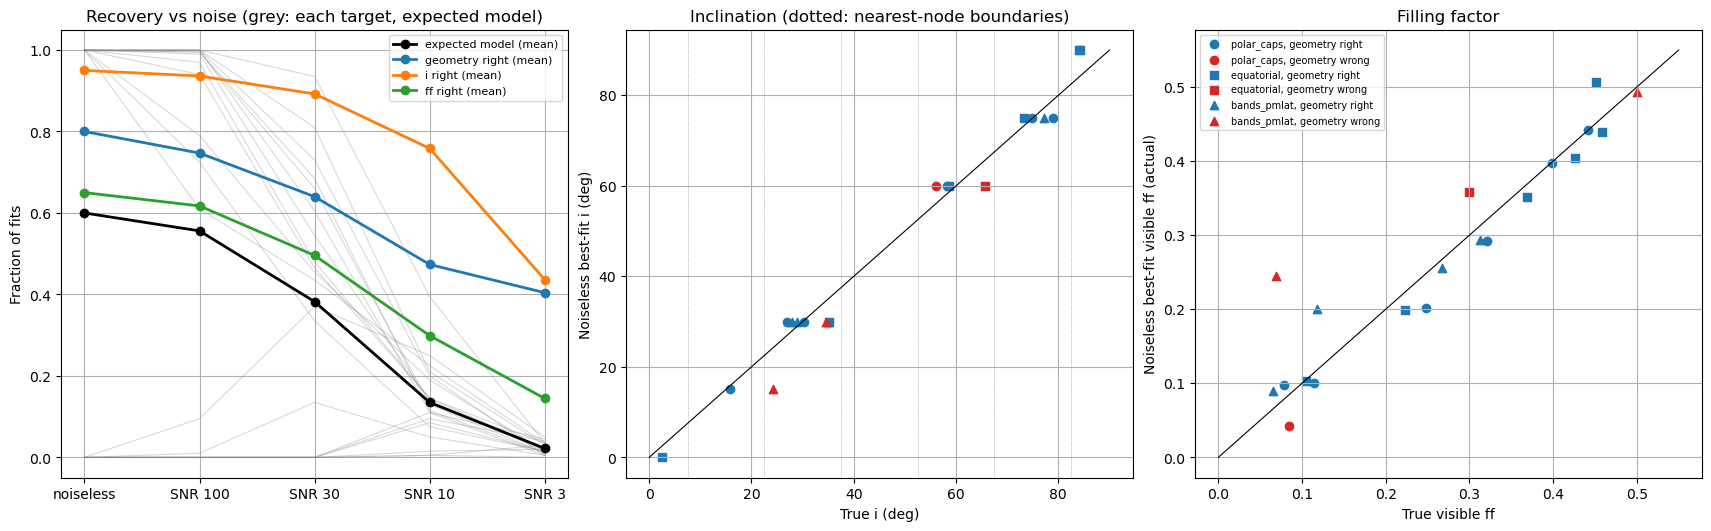

In [4]:
# ----- chi^2 fit on the 7 lines: noiseless and noisy -----
snr_levels = [100, 30, 10, 3]   # per 0.0087 A bin
n_realisations = 200
fit_labels = ['noiseless'] + [f'SNR {snr}' for snr in snr_levels]


def best_models(observed, truth, snr):
    """Best-fit model index for each row of observed (n_realisations, n_fit_bins), sigma = truth / snr."""
    chi2 = np.zeros((observed.shape[0], n_models))
    for n in range(n_models):
        chi2[:, n] = np.sum(((observed - model_matrix[n]) / (truth / snr)) ** 2, axis=1)
    return np.argmin(chi2, axis=1)


# Fraction of fits, per target and fit, that get everything / geometry / i node / ff node right.
# ff node right: the same nominal ff step as the expected model (its nearest actual visible ff).
score_names = ['exact', 'geometry', 'i', 'ff']
scores = {score: np.zeros((n_perturbed, len(fit_labels))) for score in score_names}
noiseless_best = np.zeros(n_perturbed, dtype=int)
most_frequent = np.zeros((n_perturbed, len(fit_labels)), dtype=int)
for t, run in enumerate(perturbed_runs):
    truth = target_matrix[t]
    fits = [best_models(truth[None, :], truth, 1)]   # noiseless: the SNR scale does not change the argmin
    for j, snr in enumerate(snr_levels):
        rng = np.random.default_rng([0, t, j])
        observed = truth + rng.normal(size=(n_realisations, truth.size)) * truth / snr
        fits.append(best_models(observed, truth, snr))
    noiseless_best[t] = fits[0][0]
    for j, best in enumerate(fits):
        scores['exact'][t, j] = np.mean(best == run['expected'])
        scores['geometry'][t, j] = np.mean(model_geometry[best] == run['grid_geometry'])
        scores['i'][t, j] = np.mean(model_inc[best] == run['inc_node'])
        scores['ff'][t, j] = np.mean(np.isclose(model_target_ff[best], model_target_ff[run['expected']]))
        most_frequent[t, j] = np.bincount(best, minlength=n_models).argmax()

print(f"Fraction of fits returning the expected grid model (chance: 1/{n_models} = {1 / n_models:.3f})")
print(f"{'target':24s} {'expected model':24s} {'noiseless best':24s} " + ' '.join(f'{label:>9s}' for label in fit_labels))
for t, run in enumerate(perturbed_runs):
    print(f"{run['name']:24s} {model_names[run['expected']]:24s} {model_names[noiseless_best[t]]:24s} "
          + ' '.join(f'{value:9.2f}' for value in scores['exact'][t]))
print(f"{'mean':74s}" + ' '.join(f'{value:9.2f}' for value in scores['exact'].mean(axis=0)))
for score in score_names[1:]:
    print(f"{'mean, ' + score + ' right':74s}" + ' '.join(f'{value:9.2f}' for value in scores[score].mean(axis=0)))

print("\nMost frequent best model at SNR 30, where it differs from the expected one:")
snr30 = fit_labels.index('SNR 30')
for t, run in enumerate(perturbed_runs):
    if most_frequent[t, snr30] != run['expected']:
        print(f"  {run['name']:24s} expected {model_names[run['expected']]:24s} got {model_names[most_frequent[t, snr30]]}")

# ----- plot -----
geometry_marker = {'polar_caps': 'o', 'equatorial': 's', 'bands_pmlat': '^'}
target_inc = np.array([run['inc'] for run in perturbed_runs])
target_ff = np.array([run['visible_ff'] for run in perturbed_runs])
geometry_right = model_geometry[noiseless_best] == np.array([run['grid_geometry'] for run in perturbed_runs])
fig, axes = plt.subplots(1, 3, figsize=(17, 5.2), constrained_layout=True)
positions = np.arange(len(fit_labels))
for t in range(n_perturbed):
    axes[0].plot(positions, scores['exact'][t], color='grey', alpha=0.3, linewidth=0.8)
for score, colour in zip(score_names, ['k', 'tab:blue', 'tab:orange', 'tab:green']):
    axes[0].plot(positions, scores[score].mean(axis=0), marker='o', color=colour, linewidth=2,
                 label=f'{score} right (mean)' if score != 'exact' else 'expected model (mean)')
axes[0].set_xticks(positions)
axes[0].set_xticklabels(fit_labels)
axes[0].set_ylabel('Fraction of fits')
axes[0].set_title('Recovery vs noise (grey: each target, expected model)')
axes[0].legend(fontsize=8)
axes[0].grid(True)
for geometry, marker in geometry_marker.items():
    for right, colour in ((True, 'tab:blue'), (False, 'tab:red')):
        chosen = np.array([run['geometry'] == geometry for run in perturbed_runs]) & (geometry_right == right)
        if not np.any(chosen):
            continue
        label = f"{geometry}, geometry {'right' if right else 'wrong'}"
        axes[1].scatter(target_inc[chosen], model_inc[noiseless_best[chosen]], marker=marker, color=colour, label=label)
        axes[2].scatter(target_ff[chosen], model_ff[noiseless_best[chosen]], marker=marker, color=colour, label=label)
for inc_node in grid_incs[:-1] + 7.5:   # boundaries of the nearest-node cells
    axes[1].axvline(inc_node, color='grey', linewidth=0.5, linestyle=':')
axes[1].plot([0, 90], [0, 90], color='k', linewidth=0.8)
axes[1].set_xlabel('True i (deg)')
axes[1].set_ylabel('Noiseless best-fit i (deg)')
axes[1].set_title('Inclination (dotted: nearest-node boundaries)')
axes[1].grid(True)
axes[2].plot([0, 0.55], [0, 0.55], color='k', linewidth=0.8)
axes[2].set_xlabel('True visible ff')
axes[2].set_ylabel('Noiseless best-fit visible ff (actual)')
axes[2].set_title('Filling factor')
axes[2].legend(fontsize=7)
axes[2].grid(True)
plt.show()


/rds/general/user/dsy24/home/miniforge3/envs/actress_highres1/lib/python3.9/site-packages/actress-1.0-py3.9.egg/actress/run_actress_notebook.py:63: RuntimeWarning: divide by zero encountered in power
  y = I0 * (1-(a*(1-(mu**b))))


/rds/general/user/dsy24/home/miniforge3/envs/actress_highres1/lib/python3.9/site-packages/actress-1.0-py3.9.egg/actress/run_actress_notebook.py:63: RuntimeWarning: divide by zero encountered in power
  y = I0 * (1-(a*(1-(mu**b))))


/rds/general/user/dsy24/home/miniforge3/envs/actress_highres1/lib/python3.9/site-packages/actress-1.0-py3.9.egg/actress/run_actress_notebook.py:63: RuntimeWarning: divide by zero encountered in power
  y = I0 * (1-(a*(1-(mu**b))))


/rds/general/user/dsy24/home/miniforge3/envs/actress_highres1/lib/python3.9/site-packages/actress-1.0-py3.9.egg/actress/run_actress_notebook.py:63: RuntimeWarning: divide by zero encountered in power
  y = I0 * (1-(a*(1-(mu**b))))


/rds/general/user/dsy24/home/miniforge3/envs/actress_highres1/lib/python3.9/site-packages/actress-1.0-py3.9.egg/actress/run_actress_notebook.py:63: RuntimeWarning: divide by zero encountered in power
  y = I0 * (1-(a*(1-(mu**b))))


/rds/general/user/dsy24/home/miniforge3/envs/actress_highres1/lib/python3.9/site-packages/actress-1.0-py3.9.egg/actress/run_actress_notebook.py:63: RuntimeWarning: divide by zero encountered in power
  y = I0 * (1-(a*(1-(mu**b))))


/rds/general/user/dsy24/home/miniforge3/envs/actress_highres1/lib/python3.9/site-packages/actress-1.0-py3.9.egg/actress/run_actress_notebook.py:63: RuntimeWarning: divide by zero encountered in power
  y = I0 * (1-(a*(1-(mu**b))))


/rds/general/user/dsy24/home/miniforge3/envs/actress_highres1/lib/python3.9/site-packages/actress-1.0-py3.9.egg/actress/run_actress_notebook.py:63: RuntimeWarning: divide by zero encountered in power
  y = I0 * (1-(a*(1-(mu**b))))


Simulated 20 runs x 11473 wavelengths in 10.6 min
Wrote ./outputs/gridsearch/4_gridsearch_lines_perturbed_full_v4000_res3d5_res2d200_7lines_seed0_n20.npz
Full spectra match the windowed ones on the 7 windows (max |relative difference| <= 1e-12)


Fits on the 354-line and full sets: 3.9 min

Noiseless best model per target (7 lines, all 354 lines, full 430-440 nm); * = the expected model
perturbed00_bands_pmlat  equatorial_ff0.25_i15      equatorial_ff0.05_i30      equatorial_ff0.05_i30    
perturbed01_equatorial   equatorial_ff0.45_i75   *  equatorial_ff0.45_i75   *  equatorial_ff0.45_i75   *
perturbed02_equatorial   bands_pm30_ff0.35_i60      bands_pm30_ff0.35_i60      bands_pm30_ff0.35_i60    
perturbed03_equatorial   equatorial_ff0.40_i90   *  equatorial_ff0.40_i90   *  equatorial_ff0.40_i90   *
perturbed04_bands_pmlat  bands_pm30_ff0.10_i75      bands_pm30_ff0.10_i75      bands_pm30_ff0.10_i75    
perturbed05_polar_caps   polar_caps_ff0.45_i15   *  polar_caps_ff0.45_i15   *  polar_caps_ff0.45_i15   *
perturbed06_polar_caps   polar_caps_ff0.20_i30      polar_caps_ff0.20_i30      polar_caps_ff0.20_i30    
perturbed07_equatorial   equatorial_ff0.10_i0    *  equatorial_ff0.10_i0    *  equatorial_ff0.10_i0    *
perturbed08_polar

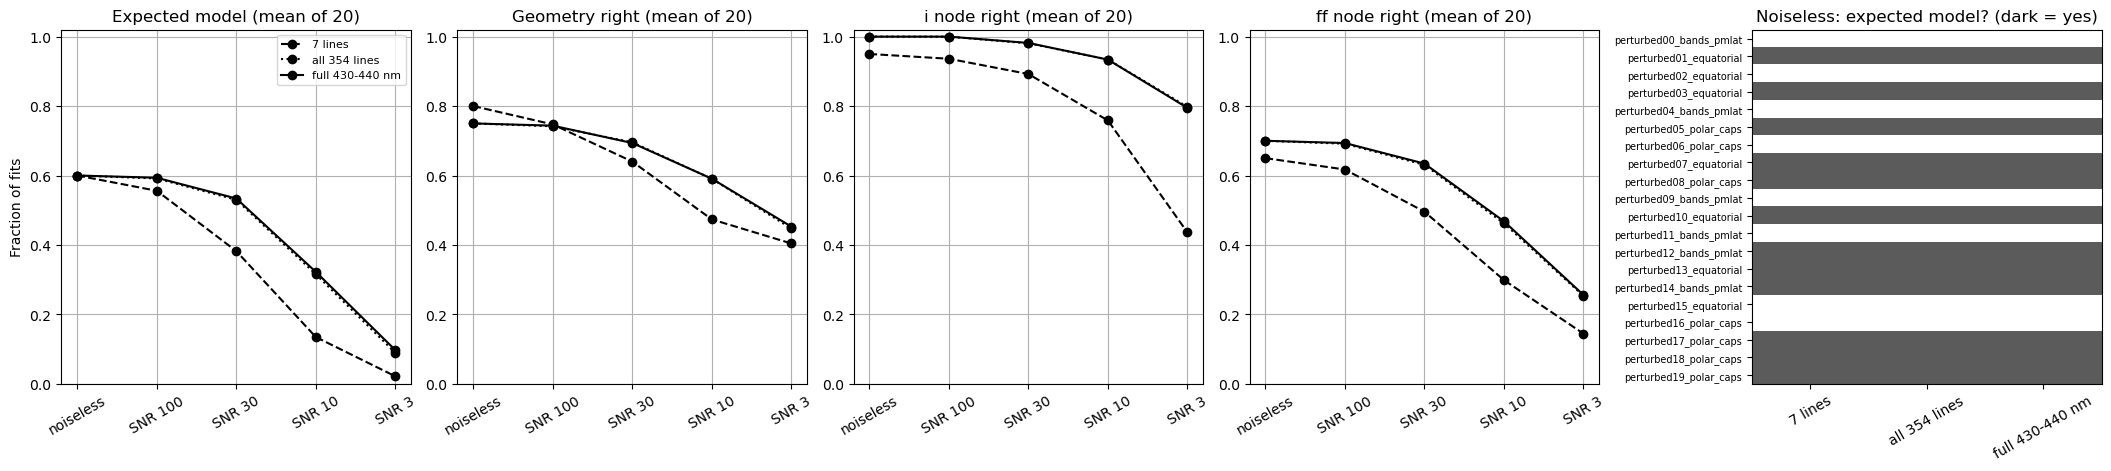

In [5]:
# ----- 7 lines vs all 354 lines vs the full 430-440 nm spectrum -----
# The targets are re-simulated over the whole range with notebook 3's simulate_grid_spectrum; the grid
# models already have full spectra in the dense cache. The 354-line and full sets are normalised by each
# spectrum's mean over all common bins (as in notebook 3), so one noise realisation on the common bins
# serves both; the 7-line results are cell 4's. SNR is per 0.0087 A bin in every set, so the full
# spectrum has ~36x the bins of the 7 lines: the noisy columns mostly show that, and the noiseless
# column shows what the extra bins add once noise is gone.
perturbed_full_cache_file = perturbed_cache_file.replace('_perturbed_', '_perturbed_full_')

perturbed_full_raw = {}
if os.path.exists(perturbed_full_cache_file):
    cached = np.load(perturbed_full_cache_file)
    if not (np.array_equal(cached['run_names'], perturbed_names) and np.array_equal(cached['config'], perturbed_config)
            and np.array_equal(cached['strip_edges'], perturbed_strip_edges)
            and np.array_equal(cached['common_bins'], common_bins)):
        raise ValueError(f"{perturbed_full_cache_file} was made with different runs or settings. "
                         "Delete or rename it by hand if it should be replaced.")
    for name in perturbed_names:
        perturbed_full_raw[name] = cached[f'spectrum_{name}']
    print(f"Loaded {len(perturbed_full_raw)} full spectra from {perturbed_full_cache_file}")
else:
    t_start = time.time()
    ctx = mp.get_context('fork')
    with ctx.Pool(processes=grid_n_workers) as pool:
        results = pool.map(simulate_grid_spectrum, perturbed_runs, chunksize=1)
    for run, (bins, spectrum, image) in zip(perturbed_runs, results):
        perturbed_full_raw[run['name']] = on_common_bins(bins, spectrum, run['name'])
    print(f"Simulated {n_perturbed} runs x {len(grid_input_wavelengths)} wavelengths in {(time.time() - t_start) / 60:.1f} min")
    to_save = {'run_names': perturbed_names, 'config': perturbed_config, 'strip_edges': perturbed_strip_edges,
               'common_bins': common_bins}
    for name in perturbed_names:
        to_save[f'spectrum_{name}'] = perturbed_full_raw[name]
    np.savez(perturbed_full_cache_file, **to_save)
    print(f"Wrote {perturbed_full_cache_file}")

# The full simulation must reproduce the windowed one (cell 3) on the 7 windows.
for name in perturbed_names:
    spectrum = perturbed_full_raw[name]
    if not np.all(np.isfinite(spectrum)) or np.any(spectrum <= 0):
        raise ValueError(f"{name}: non-finite or non-positive intensity in the full spectrum")
    difference = np.max(np.abs(spectrum[fit_bins] / perturbed_raw[name] - 1))
    if difference > 1e-12:
        raise ValueError(f"{name}: full and windowed spectra differ by {difference:.2e} on the fit bins")
print("Full spectra match the windowed ones on the 7 windows (max |relative difference| <= 1e-12)")

model_full = np.array([on_common_bins(dense_cache[f'bins_{name}'], dense_cache[f'spectrum_{name}'], name)
                       for name in model_names])
model_full = model_full / model_full.mean(axis=1, keepdims=True)   # (n_models, n_bins), each / its own mean
target_full = np.array([perturbed_full_raw[name] for name in perturbed_names])
target_full = target_full / target_full.mean(axis=1, keepdims=True)
full_bin_sets = {f'all {n_lines} lines': in_any_line, 'full 430-440 nm': np.ones(n_bins, dtype=bool)}


def best_models_on(models, observed, truth, snr):
    """Best-fit row of models (n_models, n) for each row of observed (n_realisations, n), sigma = truth / snr."""
    chi2 = np.zeros((observed.shape[0], len(models)))
    for n in range(len(models)):
        chi2[:, n] = np.sum(((observed - models[n]) / (truth / snr)) ** 2, axis=1)
    return np.argmin(chi2, axis=1)


# set_scores[set][score]: (n_perturbed, n_fits), scored as in cell 4; the 7-line set is cell 4's.
set_scores = {f'{n_selected} lines': scores}
set_noiseless_best = {f'{n_selected} lines': noiseless_best}
for set_name in full_bin_sets:
    set_scores[set_name] = {score: np.zeros((n_perturbed, len(fit_labels))) for score in score_names}
    set_noiseless_best[set_name] = np.zeros(n_perturbed, dtype=int)
t_start = time.time()
for t, run in enumerate(perturbed_runs):
    truth = target_full[t]
    observed_sets = [truth[None, :]]   # noiseless first, then one set of realisations per SNR
    for j, snr in enumerate(snr_levels):
        rng = np.random.default_rng([1, t, j])   # 1: a stream separate from cell 4's
        observed_sets.append(truth + rng.normal(size=(n_realisations, n_bins)) * truth / snr)
    for set_name, bins_mask in full_bin_sets.items():
        for j, observed in enumerate(observed_sets):
            snr = 1 if j == 0 else snr_levels[j - 1]   # noiseless: the SNR scale does not change the argmin
            best = best_models_on(model_full[:, bins_mask], observed[:, bins_mask], truth[bins_mask], snr)
            if j == 0:
                set_noiseless_best[set_name][t] = best[0]
            set_scores[set_name]['exact'][t, j] = np.mean(best == run['expected'])
            set_scores[set_name]['geometry'][t, j] = np.mean(model_geometry[best] == run['grid_geometry'])
            set_scores[set_name]['i'][t, j] = np.mean(model_inc[best] == run['inc_node'])
            set_scores[set_name]['ff'][t, j] = np.mean(np.isclose(model_target_ff[best], model_target_ff[run['expected']]))
print(f"Fits on the 354-line and full sets: {(time.time() - t_start) / 60:.1f} min")

set_names = list(set_scores)
print(f"\nNoiseless best model per target ({', '.join(set_names)}); * = the expected model")
for t, run in enumerate(perturbed_runs):
    best_text = '  '.join(f"{model_names[set_noiseless_best[s][t]]:24s}{'*' if set_noiseless_best[s][t] == run['expected'] else ' '}"
                          for s in set_names)
    print(f"{run['name']:24s} {best_text}")
print(f"\n{'mean fraction':30s}" + ' '.join(f'{label:>9s}' for label in fit_labels))
for score in score_names:
    for set_name in set_names:
        print(f"{score + ', ' + set_name:30s}" + ' '.join(f'{value:9.2f}' for value in set_scores[set_name][score].mean(axis=0)))

# ----- plot -----
set_style = {set_names[0]: '--', set_names[1]: ':', set_names[2]: '-'}
score_title = {'exact': 'Expected model', 'geometry': 'Geometry right', 'i': 'i node right', 'ff': 'ff node right'}
fig, axes = plt.subplots(1, len(score_names) + 1, figsize=(4.2 * (len(score_names) + 1), 4.6), constrained_layout=True)
positions = np.arange(len(fit_labels))
for ax, score in zip(axes, score_names):
    for set_name in set_names:
        ax.plot(positions, set_scores[set_name][score].mean(axis=0), marker='o', color='k',
                linestyle=set_style[set_name], label=set_name)
    ax.set_xticks(positions)
    ax.set_xticklabels(fit_labels, rotation=30)
    ax.set_ylim(0, 1.02)
    ax.set_title(f'{score_title[score]} (mean of {n_perturbed})')
    ax.grid(True)
axes[0].set_ylabel('Fraction of fits')
axes[0].legend(fontsize=8)
noiseless_match = np.array([[set_noiseless_best[s][t] == run['expected'] for s in set_names]
                            for t, run in enumerate(perturbed_runs)], dtype=float)
axes[-1].imshow(noiseless_match, cmap='Greys', vmin=0, vmax=1.4, aspect='auto')
axes[-1].set_xticks(range(len(set_names)))
axes[-1].set_xticklabels(set_names, rotation=30)
axes[-1].set_yticks(range(n_perturbed))
axes[-1].set_yticklabels(perturbed_names, fontsize=7)
axes[-1].set_title('Noiseless: expected model? (dark = yes)')
plt.show()
